# CPU and GPU Monte Carlo on your laptop

Author: Fred J. Hickernell · MATH 565, Fall 2026

Companion to **Selected Topics: parallel computing**, adapted from the Fall 2025 GPU demo

Compare the same Monte Carlo calculation using NumPy CPU float64/float32, PyTorch CPU float32, and an available GPU in float32. Then evaluate many expectations together using bounded batches

**On Mini, M3, or M5:** select the course `qmcpy` kernel and Run All. The device summary should report **MPS — Apple GPU**. This notebook never changes system power settings or installs packages locally. If PyTorch is missing, the NumPy comparisons still run; install the optional dependency in the course environment with `python -m pip install torch`, restart the kernel, and rerun

The extended sweep reaches 16,777,216 samples and may take a minute or two on Mini; exact runtime depends on the machine. Small cases show overhead and large cases expose throughput. Adjust the parameter cell after the first run. GPU speedup depends on hardware, workload, precision, and overhead; it is not promised

Local execution is the intended classroom workflow. The conditional setup cell also supports the course's usual Colab environment, where an available CUDA GPU may be used

In [1]:
from pathlib import Path
import shutil
import subprocess
import sys
import time

NOTEBOOK_START_TIME = time.perf_counter()

colab = "google.colab" in sys.modules
if colab:
    print("Setting up this course's recorded classlib, QMCPy, and TeX; this may take several minutes …")
    course_checkout = Path("/content/MATH565Fall2026")
    if not course_checkout.exists():
        subprocess.run(
            [
                "git", "clone", "--quiet", "--depth", "1",
                "https://github.com/fjhickernell/MATH565Fall2026.git",
                str(course_checkout),
            ],
            check=True,
        )
    subprocess.run(
        [
            "git", "-C", str(course_checkout),
            "-c", "submodule.classlib.url=https://github.com/fjhickernell/HickernellAcademicLib.git",
            "-c", "submodule.qmcpy.url=https://github.com/QMCSoftware/qmcpy.git",
            "submodule", "update", "--init", "classlib", "qmcpy",
        ],
        check=True,
    )
    if shutil.which("latex") is None:
        subprocess.run(
            [
                "apt-get", "-qq", "install", "-y",
                "cm-super", "dvipng", "texlive-latex-extra",
                "texlive-latex-recommended",
            ],
            check=True,
        )
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "-q",
            str(course_checkout / "classlib"),
            str(course_checkout / "qmcpy"),
        ],
        check=True,
    )
    print("Colab setup complete.")
    print("For faster repeated work, use the local `qmcpy` environment.")

In [2]:
import platform
import json
import subprocess
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import classlib as cl
from IPython.display import display, Markdown

cl.nbviz.init(use_tex=True)
colors = cl.nbviz.TOL_BRIGHT

try:
    import torch
except ImportError:
    torch = None

# Change parameters here, then Run All
SEED = 5652026
FORCE_CPU = False
D = 12
SAMPLE_SIZES = [2**12, 2**16, 2**20, 2**22, 2**23, 2**24]
REPLICATIONS = 8
SAMPLE_BATCH = 2**16
MANY_N = 2**18
CENTER_COUNTS = [1, 8, 32, 128, 512]
CENTER_BATCH = 64
MANY_REPLICATIONS = 3
DIAGNOSTIC_BATCHES = [2**12, 2**16, 2**18]
DIAGNOSTIC_REPEATS = 5
BATCH_SWEEP_N = 2**20
BATCH_SWEEP_REPEATS = 3

assert D >= 1 and REPLICATIONS >= 2 and MANY_REPLICATIONS >= 2
assert SAMPLE_BATCH > 0 and CENTER_BATCH > 0 and MANY_N > 0
assert all(n > 0 for n in SAMPLE_SIZES + CENTER_COUNTS)

if torch is not None and not FORCE_CPU and torch.backends.mps.is_available():
    gpu_device = 'mps'
elif torch is not None and not FORCE_CPU and torch.cuda.is_available():
    gpu_device = 'cuda'
else:
    gpu_device = None

# Read only model/chip labels and core counts; never print serial numbers or hardware UUIDs
machine_info = {
    'machine': platform.system() + ' ' + platform.machine(),
    'processor': platform.processor() or 'not reported',
    'logical_cores': os.cpu_count(),
    'gpu_cores': 'not reported',
}
if platform.system() == 'Darwin':
    try:
        result = subprocess.run(
            ['/usr/sbin/system_profiler', 'SPHardwareDataType', 'SPDisplaysDataType', '-json'],
            capture_output=True, text=True, check=True, timeout=10,
        )
        profile = json.loads(result.stdout)
        hardware = profile.get('SPHardwareDataType', [{}])[0]
        machine_info['machine'] = '{} ({})'.format(
            hardware.get('machine_name', 'Mac'),
            hardware.get('machine_model', platform.machine()),
        )
        machine_info['processor'] = hardware.get('chip_type') or hardware.get('cpu_type') or machine_info['processor']
        gpu = next(iter(profile.get('SPDisplaysDataType', [])), {})
        machine_info['gpu_cores'] = gpu.get('sppci_cores') or 'not reported'
    except (OSError, subprocess.SubprocessError, ValueError, KeyError, IndexError):
        pass  # Keep portable fallback labels if hardware lookup is unavailable


def display_benchmark_summary(frame):
    frame.attrs.update(machine_info)
    display(Markdown(
        f"**Machine:** {machine_info['machine']} | "
        f"**Processor:** {machine_info['processor']} | "
        f"**Logical CPU cores:** {machine_info['logical_cores']} | "
        f"**GPU cores:** {machine_info['gpu_cores']}"
    ))
    display(frame)

print(f"Machine: {machine_info['machine']} | Processor: {machine_info['processor']}")
print(f'Python {platform.python_version()} | {platform.machine()} | {os.cpu_count()} logical CPU cores')
print(f"GPU cores: {machine_info['gpu_cores']}")
print(f'NumPy {np.__version__} | PyTorch {torch.__version__ if torch is not None else "not installed"}')
print('GPU backend:', {'mps': 'MPS — Apple GPU', 'cuda': 'CUDA — NVIDIA GPU'}.get(gpu_device, 'none — GPU rows are skipped'))
print(f'NumPy baseline: float64 and float32 | dimension {D} | {REPLICATIONS} replications')
print(f'Sample sizes: {SAMPLE_SIZES} | sample batch: {SAMPLE_BATCH}')
print('Saved timings describe this machine; rerun on the classroom M3 for M3 results')
if torch is not None:
    print(f'PyTorch CPU threads: {torch.get_num_threads()}')

Machine: MacBook Pro (Mac15,8) | Processor: Apple M3 Max
Python 3.13.13 | arm64 | 16 logical CPU cores
GPU cores: 40
NumPy 2.4.6 | PyTorch 2.12.0
GPU backend: MPS — Apple GPU
NumPy baseline: float64 and float32 | dimension 12 | 8 replications
Sample sizes: [4096, 65536, 1048576, 4194304, 8388608, 16777216] | sample batch: 65536
Saved timings describe this machine; rerun on the classroom M3 for M3 results
PyTorch CPU threads: 12


## Same expectation, different hardware

For $\boldsymbol X\sim\operatorname{Norm}(\boldsymbol0,I_d)$, estimate
$$
\mu=\mathbb E[f(\boldsymbol X)]=1,
\qquad f(\boldsymbol x)=2^{d/2}\exp(-\|\boldsymbol x\|^2/2)
$$
The normalization makes the exact answer one in every dimension. Also
$$
\operatorname{var}\{f(\boldsymbol X)\}=(2/\sqrt3)^d-1,
\qquad \operatorname{RMSE}(\widehat\mu_n)=\sqrt{\operatorname{var}\{f(\boldsymbol X)\}/n}
$$

This notebook deliberately uses **native NumPy/PyTorch random generators** to include generation in each backend's timing. It benchmarks hardware implementations rather than introducing another course sampling interface. NumPy and PyTorch seeds do not generate identical samples

CPU float32 versus CPU float64 explores precision and implementation cost. PyTorch CPU float32 versus PyTorch GPU float32 gives a closer comparison of hardware backends. Separate backend kernels and generators still differ

In [3]:
def synchronize(device):
    if torch is not None and device == 'mps':
        torch.mps.synchronize()
    elif torch is not None and device == 'cuda':
        torch.cuda.synchronize()


def seed_torch(seed):
    torch.manual_seed(seed)
    if gpu_device == 'mps':
        torch.mps.manual_seed(seed)
    elif gpu_device == 'cuda':
        torch.cuda.manual_seed_all(seed)


def numpy_mean(n, d, seed, dtype):
    rng = np.random.default_rng(seed)
    total = np.float64(0)
    for start in range(0, n, SAMPLE_BATCH):
        size = min(SAMPLE_BATCH, n-start)
        x = rng.standard_normal((size, d), dtype=dtype)
        squared_norm = np.sum(x*x, axis=1, dtype=dtype)
        values = np.exp(-dtype(0.5)*squared_norm) * dtype(2**(d/2))
        total += values.sum(dtype=dtype)
    return float(total/n)


def torch_mean(n, d, seed, device):
    seed_torch(seed)
    with torch.inference_mode():
        total = torch.zeros((), device=device, dtype=torch.float32)
        for start in range(0, n, SAMPLE_BATCH):
            size = min(SAMPLE_BATCH, n-start)
            x = torch.randn((size, d), device=device, dtype=torch.float32)
            values = torch.exp(-0.5*(x*x).sum(dim=1)) * (2**(d/2))
            total += values.sum()
        return float((total/n).item())


methods = [
    ('NumPy CPU64', 'cpu', lambda n, d, seed: numpy_mean(n, d, seed, np.float64)),
    ('NumPy CPU32', 'cpu', lambda n, d, seed: numpy_mean(n, d, seed, np.float32)),
]
if torch is not None:
    methods.append(('Torch CPU32', 'cpu', lambda n, d, seed: torch_mean(n, d, seed, 'cpu')))
if gpu_device is not None:
    methods.append((f'Torch {gpu_device.upper()}32', gpu_device,
                    lambda n, d, seed: torch_mean(n, d, seed, gpu_device)))


def timed_call(func, device, *args):
    synchronize(device)
    started = time.perf_counter()
    result = func(*args)
    synchronize(device)
    return result, time.perf_counter()-started


# Warm up kernels and device initialization outside measured replications
for _, device, func in methods:
    func(min(SAMPLE_BATCH, SAMPLE_SIZES[0]), D, SEED-1)
    synchronize(device)
print('Methods:', ', '.join(name for name, _, _ in methods))

Methods: NumPy CPU64, NumPy CPU32, Torch CPU32, Torch MPS32


## Apple Silicon and the GPU backend

Apple Silicon uses **Metal/MPS**, not NVIDIA CUDA. PyTorch supports MPS GPU execution; CUDA-only code and libraries do not run on the Apple GPU

This notebook explicitly uses float32 for MPS, which does not support float64 tensors. CPU64 remains useful as a precision comparison, while Torch CPU32 versus GPU32 is the closer backend comparison

A slower GPU result is not evidence that parallel computing is unavailable. Small operations, dispatch, synchronization, random generation, and backend implementations can dominate. The next experiments separate some of those costs rather than assuming their cause

Sources: [Apple: accelerated PyTorch on Mac](https://developer.apple.com/metal/pytorch/), [PyTorch MPS backend and precision](https://docs.pytorch.org/docs/main/notes/mps.html)

The stage table can reveal slower CPU random generation even when CPU tensor evaluation is fast. Read those measurements before attributing a complete-run gap to the GPU platform

## Timing independent complete runs

Each timed run includes sample generation, integrand evaluation, batch reductions, and return of the estimate to the CPU. GPU synchronization prevents asynchronous work from escaping the timer. Warmup, plotting, and notebook setup are excluded

All methods use the same batch limit. Seed assignment is explicit, with a separate seed for every method, sample size, and replication. Timings remain machine-specific and can change with background activity and power mode

In [4]:
records = []
for j, n in enumerate(SAMPLE_SIZES):
    for r in range(REPLICATIONS):
        # Rotate order to reduce systematic first/last-method timing effects
        order = list(range(len(methods)))
        order = order[r % len(order):] + order[:r % len(order)]
        for k in order:
            name, device, func = methods[k]
            seed = SEED + 100_000*k + 1000*j + r
            estimate, elapsed = timed_call(func, device, n, D, seed)
            records.append(dict(n=n, replication=r, method=name,
                                estimate=estimate, error=estimate-1, seconds=elapsed))
runs = pd.DataFrame(records)
assert np.isfinite(runs[['estimate', 'seconds']]).all().all()
assert (runs.seconds > 0).all()
summary = runs.groupby(['n', 'method'], sort=False).agg(
    mean_estimate=('estimate', 'mean'),
    empirical_RMSE=('error', lambda e: np.sqrt(np.mean(np.square(e)))),
    mean_seconds=('seconds', 'mean'),
).reset_index()
variance = (2/np.sqrt(3))**D - 1
summary['theoretical_RMSE'] = np.sqrt(variance/summary.n)
baseline = summary[summary.method == 'NumPy CPU64'].set_index('n').mean_seconds
summary['speedup_vs_NumPy64'] = summary.n.map(baseline)/summary.mean_seconds
summary['million_points_per_second'] = summary.n/summary.mean_seconds/1e6
display_benchmark_summary(summary.round(6))

**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,n,method,mean_estimate,empirical_RMSE,mean_seconds,theoretical_RMSE,speedup_vs_NumPy64,million_points_per_second
0,4096,NumPy CPU64,0.995607,0.048485,0.000364,0.033580,1.000000,11.254200
1,4096,NumPy CPU32,1.006274,0.033308,0.000241,0.033580,1.512401,17.020864
2,4096,Torch CPU32,0.985428,0.029433,0.001040,0.033580,0.349929,3.938166
3,4096,Torch MPS32,1.012222,0.032226,0.001360,0.033580,0.267603,3.011661
4,65536,NumPy CPU64,1.003106,0.009511,0.005022,0.008395,1.000000,13.050065
5,65536,NumPy CPU32,1.000722,0.009082,0.003699,0.008395,1.357719,17.718319
6,65536,Torch CPU32,1.000487,0.002363,0.007327,0.008395,0.685414,8.944700
7,65536,Torch MPS32,1.002667,0.005231,0.002403,0.008395,2.089580,27.269150
8,1048576,NumPy CPU64,1.001249,0.002300,0.075509,0.002099,1.000000,13.886679
9,1048576,NumPy CPU32,0.999166,0.001487,0.057763,0.002099,1.307237,18.153179


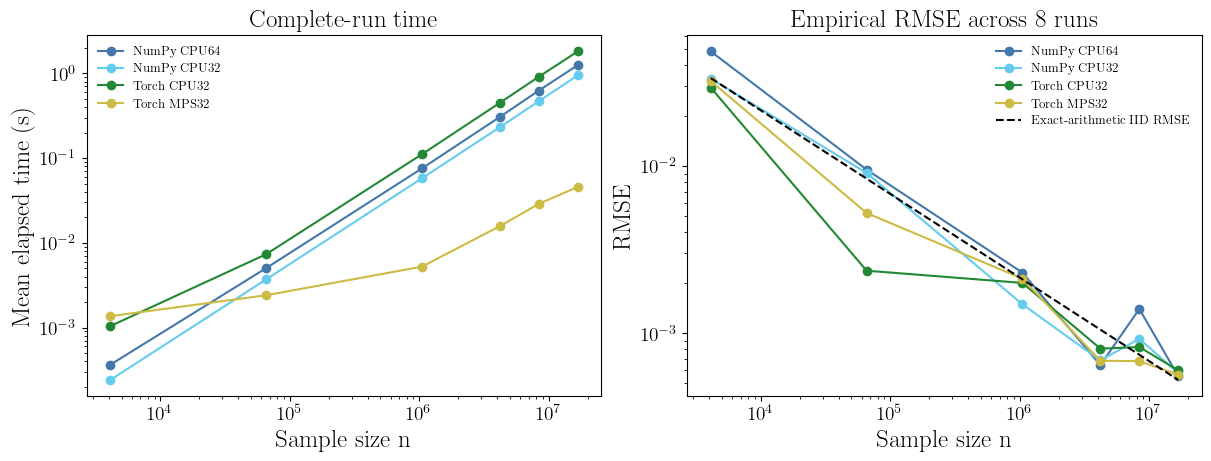

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, _, _ in methods:
    rows = summary[summary.method == name].sort_values('n')
    axes[0].loglog(rows.n, rows.mean_seconds, '-o', label=name)
    axes[1].loglog(rows.n, rows.empirical_RMSE, '-o', label=name)
axes[1].loglog(SAMPLE_SIZES, np.sqrt(variance/np.array(SAMPLE_SIZES)), '--',
               color='black', label='Exact-arithmetic IID RMSE')
axes[0].set(xlabel='Sample size n', ylabel='Mean elapsed time (s)', title='Complete-run time')
axes[1].set(xlabel='Sample size n', ylabel='RMSE', title=f'Empirical RMSE across {REPLICATIONS} runs')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,NumPy CPU64 / Torch MPS32,NumPy CPU32 / Torch MPS32,Torch CPU32 / Torch MPS32
n,,,
4096,0.268,0.177,0.765
65536,2.090,1.539,3.049
1048576,14.432,11.040,21.212
4194304,19.459,14.723,28.560
8388608,21.733,16.301,31.650
16777216,27.398,20.750,39.738


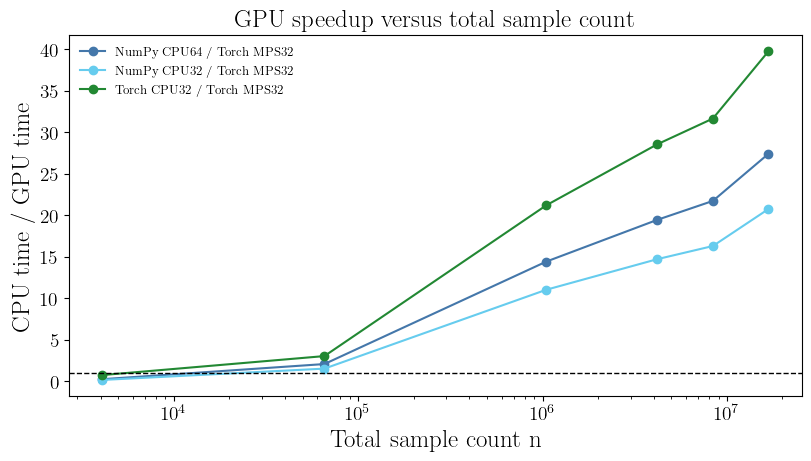

### What this run shows

- **Largest case: 16,777,216 points**, streamed in batches of 65,536
- **GPU time: 45.7 ms**
- GPU is **27.40 times faster** than NumPy CPU64 at the largest size
- GPU is **20.75 times faster** than NumPy CPU32 at the largest size
- GPU is **39.74 times faster** than Torch CPU32 at the largest size
- From **8,388,608 to 16,777,216 points**, NumPy CPU32 time grew 2.02 times and GPU time grew 1.58 times
- The same-precision NumPy CPU32/GPU speedup changed from **16.30 to 20.75**
- Over the last two sizes, speedup was **higher at the larger size** in this run; this is a descriptive comparison, not a statistical trend test
- **Fixed batch sizes bound the main working arrays**; larger total n repeats the same-sized work rather than storing a larger sample

In [6]:
# Direct speedup comparisons: a ratio above one means the GPU is faster
if gpu_device is not None:
    gpu_name = next(name for name, device, _ in methods if device == gpu_device)
    times = summary.pivot(index='n', columns='method', values='mean_seconds').sort_index()
    gpu_speedups = pd.DataFrame(index=times.index)
    for baseline_name in ['NumPy CPU64', 'NumPy CPU32', 'Torch CPU32']:
        if baseline_name in times:
            gpu_speedups[f'{baseline_name} / {gpu_name}'] = times[baseline_name]/times[gpu_name]
    display_benchmark_summary(gpu_speedups.round(3))
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    for column in gpu_speedups:
        ax.semilogx(gpu_speedups.index, gpu_speedups[column], '-o', label=column)
    ax.axhline(1, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='Total sample count n', ylabel='CPU time / GPU time', title='GPU speedup versus total sample count')
    ax.legend(fontsize=9)
    plt.show()

    largest = int(times.index[-1])
    lines = [f'### What this run shows\n',
             f'- **Largest case: {largest:,} points**, streamed in batches of {SAMPLE_BATCH:,}',
             f'- **GPU time: {1000*times.loc[largest, gpu_name]:.1f} ms**']
    for baseline_name in ['NumPy CPU64', 'NumPy CPU32', 'Torch CPU32']:
        if baseline_name in times:
            ratio = times.loc[largest, baseline_name]/times.loc[largest, gpu_name]
            relation = 'faster' if ratio >= 1 else 'slower'
            factor = ratio if ratio >= 1 else 1/ratio
            lines.append(f'- GPU is **{factor:.2f} times {relation}** than {baseline_name} at the largest size')
    if len(times) >= 2 and 'NumPy CPU32' in times:
        previous = int(times.index[-2])
        old_ratio = times.loc[previous, 'NumPy CPU32']/times.loc[previous, gpu_name]
        new_ratio = times.loc[largest, 'NumPy CPU32']/times.loc[largest, gpu_name]
        cpu_growth = times.loc[largest, 'NumPy CPU32']/times.loc[previous, 'NumPy CPU32']
        gpu_growth = times.loc[largest, gpu_name]/times.loc[previous, gpu_name]
        lines.append(f'- From **{previous:,} to {largest:,} points**, NumPy CPU32 time grew {cpu_growth:.2f} times and GPU time grew {gpu_growth:.2f} times')
        lines.append(f'- The same-precision NumPy CPU32/GPU speedup changed from **{old_ratio:.2f} to {new_ratio:.2f}**')
        change = new_ratio/old_ratio
        description = ('approximately level (within 10%)' if 0.9 <= change <= 1.1
                       else 'higher at the larger size' if change > 1.1
                       else 'lower at the larger size')
        lines.append(f'- Over the last two sizes, speedup was **{description}** in this run; this is a descriptive comparison, not a statistical trend test')
    lines.append('- **Fixed batch sizes bound the main working arrays**; larger total n repeats the same-sized work rather than storing a larger sample')
    display(Markdown('\n'.join(lines)))
else:
    display(Markdown('### What this run shows\n\n**No GPU backend is available**, so these CPU timings do not establish GPU speedup'))

### Takeaways: runtime and statistical accuracy

- **Small jobs can favor the CPU** because GPU dispatch and synchronization take time even when there is little arithmetic
- **Larger jobs amortize fixed overhead** and can expose a GPU throughput advantage
- **Speedup need not keep increasing**: with fixed-size batches, both runtimes can become proportional to total sample count, so their ratio approaches a plateau
- **The IID accuracy law is unchanged**: RMSE decreases as $n^{-1/2}$ in exact arithmetic. Hardware changes elapsed time, not that statistical rate
- **An unusually small empirical RMSE is sampling luck, not proof of superior arithmetic**. Eight replications give a noisy estimate of RMSE

**Translate speed into accuracy:** in a throughput-dominated regime, a speedup of $s$ allows about $s$ times as many IID samples in the same time, reducing RMSE by a factor of $\sqrt{s}$. Thus 16 times faster means roughly four times smaller RMSE, not 16 times smaller. This assumes comparable contribution variance and negligible floating-point error


## Generation and evaluation costs

Time **normal generation** separately from **evaluation and reduction** at three batch sizes

Evaluation uses the same NumPy-generated sample values for every backend, converted to the required dtype and device **before timing**. Allocation, casting, and transfers of these fixed inputs are excluded from evaluation timing; intermediates and scalar-result return are included. Generation includes allocating a new sample array but excludes seed initialization

Warm up each operation and synchronize GPU timings. Report medians over repeated calls. These stage timings diagnose operations; they do not have to add up to the earlier complete-run timing because allocation, reuse, and caching differ

**Shared inputs are used only in this evaluation diagnostic**. NumPy and PyTorch are both called from Python. PyTorch has its own CPU and GPU random generators; the complete-run benchmarks and the generation-only timings use each backend's native generator. The shared values isolate evaluation cost rather than reflecting any missing generator

**Read the stages before naming the bottleneck:** a GPU can win the complete calculation even if its evaluation-only time is no better than the CPU's. Faster sample generation can supply the advantage. Conversely, moving precomputed CPU samples to a GPU would add transfer cost excluded by this diagnostic


**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,batch_size,method,generation_ms,evaluation_ms
0,4096,NumPy CPU64,0.222,0.052
1,4096,NumPy CPU32,0.174,0.045
2,4096,Torch CPU32,0.368,0.131
3,4096,Torch MPS32,0.590,0.699
4,65536,NumPy CPU64,3.581,0.956
5,65536,NumPy CPU32,2.748,0.906
6,65536,Torch CPU32,6.482,0.575
7,65536,Torch MPS32,0.311,0.403
8,262144,NumPy CPU64,13.752,3.020
9,262144,NumPy CPU32,10.593,2.370


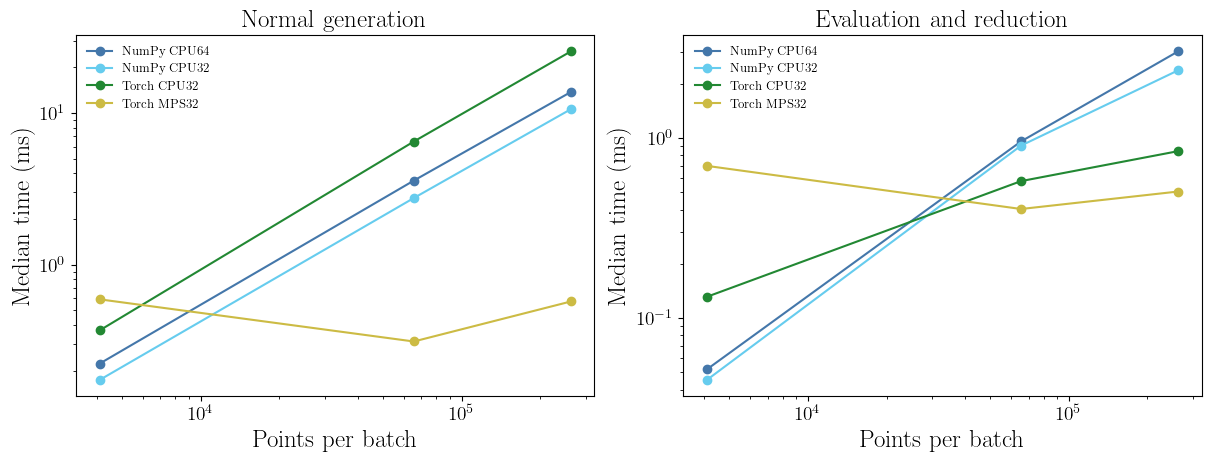

In [7]:
def numpy_evaluate(x):
    dtype = x.dtype.type
    return float((np.exp(-dtype(0.5)*np.sum(x*x, axis=1)) * dtype(2**(D/2))).mean())


def torch_evaluate(x):
    with torch.inference_mode():
        return float((torch.exp(-0.5*(x*x).sum(dim=1)) * (2**(D/2))).mean().item())


def median_operation(func, device, repeats=DIAGNOSTIC_REPEATS):
    result = func()  # untimed warmup
    synchronize(device)
    elapsed = []
    for _ in range(repeats):
        del result  # free the prior output before timing the next allocation
        result, seconds = timed_call(func, device)
        elapsed.append(seconds)
    del result
    return float(np.median(elapsed))


stage_records = []
for size in DIAGNOSTIC_BATCHES:
    fixed = np.random.default_rng(SEED+size).standard_normal((size, D))
    for k, (name, device, _) in enumerate(methods):
        if name.startswith('NumPy'):
            dtype = np.float64 if name.endswith('64') else np.float32
            rng = np.random.default_rng(SEED + 2_000_000 + size + k)
            x = fixed.astype(dtype)
            generate = lambda: rng.standard_normal((size, D), dtype=dtype)
            evaluate = lambda: numpy_evaluate(x)
        else:
            seed_torch(SEED + 2_000_000 + size + k)
            x = torch.as_tensor(fixed.astype(np.float32), device=device)
            generate = lambda: torch.randn((size, D), dtype=torch.float32, device=device)
            evaluate = lambda: torch_evaluate(x)
        generation = median_operation(generate, device)
        evaluation = median_operation(evaluate, device)
        stage_records.append(dict(batch_size=size, method=name,
                                  generation_ms=1000*generation,
                                  evaluation_ms=1000*evaluation))
        del x
    del fixed
stage_times = pd.DataFrame(stage_records)
display_benchmark_summary(stage_times.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, _, _ in methods:
    rows = stage_times[stage_times.method == name].sort_values('batch_size')
    axes[0].loglog(rows.batch_size, rows.generation_ms, '-o', label=name)
    axes[1].loglog(rows.batch_size, rows.evaluation_ms, '-o', label=name)
axes[0].set(xlabel='Points per batch', ylabel='Median time (ms)', title='Normal generation')
axes[1].set(xlabel='Points per batch', ylabel='Median time (ms)', title='Evaluation and reduction')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

## Same sample count, different batch size

Hold the total number of points fixed and change **points per batch**. This isolates batching from increasing statistical sample size

The sampling law and exact-arithmetic IID RMSE remain unchanged, while dispatch frequency and memory traffic change. Random samples can change when batch size changes, particularly for backend generators, so this is a runtime comparison rather than a paired-error experiment

**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,batch_size,method,seconds
0,4096,NumPy CPU64,0.066831
1,4096,NumPy CPU32,0.054179
2,4096,Torch CPU32,0.136279
3,4096,Torch MPS32,0.033528
4,65536,NumPy CPU64,0.076843
5,65536,NumPy CPU32,0.057103
6,65536,Torch CPU32,0.112016
7,65536,Torch MPS32,0.005509
8,262144,NumPy CPU64,0.066896
9,262144,NumPy CPU32,0.052880


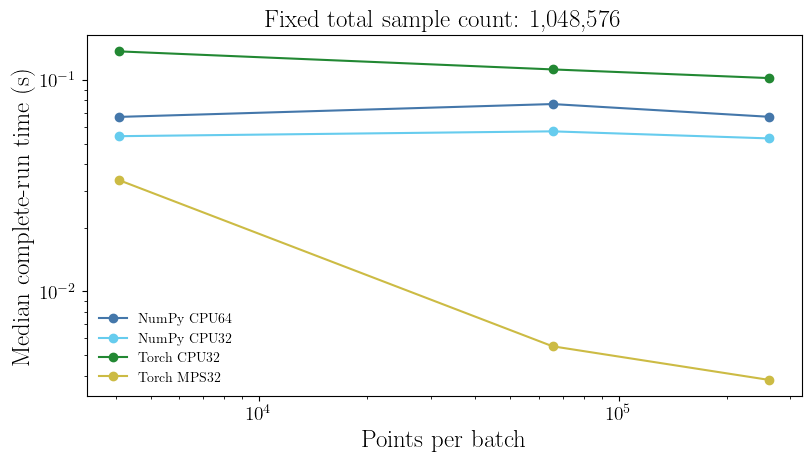

In [8]:
batch_records = []
original_batch = SAMPLE_BATCH
try:
    for size in DIAGNOSTIC_BATCHES:
        SAMPLE_BATCH = size
        for r in range(BATCH_SWEEP_REPEATS):
            order = list(range(len(methods)))
            order = order[r % len(order):] + order[:r % len(order)]
            for k in order:
                name, device, func = methods[k]
                estimate, elapsed = timed_call(func, device, BATCH_SWEEP_N, D,
                                                SEED+3_000_000+1000*k+r)
                batch_records.append(dict(batch_size=size, method=name, seconds=elapsed))
finally:
    SAMPLE_BATCH = original_batch
batch_runs = pd.DataFrame(batch_records)
batch_summary = batch_runs.groupby(['batch_size', 'method'], sort=False).seconds.median().reset_index()
display_benchmark_summary(batch_summary.round(6))
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
for name, _, _ in methods:
    rows = batch_summary[batch_summary.method == name].sort_values('batch_size')
    ax.loglog(rows.batch_size, rows.seconds, '-o', label=name)
ax.set(xlabel='Points per batch', ylabel='Median complete-run time (s)',
       title=f'Fixed total sample count: {BATCH_SWEEP_N:,}')
ax.legend(fontsize=10)
plt.show()

In [9]:
size = max(DIAGNOSTIC_BATCHES)
rows = stage_times[stage_times.batch_size == size].set_index('method')
lines = [f'### Takeaways from the diagnostic timings\n',
         f'- At **{size:,} points per batch**, generation and evaluation are timed separately']
if 'Torch CPU32' in rows.index:
    for name in ['NumPy CPU32', 'Torch CPU32']:
        lines.append(f'- **{name}:** normal generation {rows.loc[name, "generation_ms"]:.3f} ms; evaluation {rows.loc[name, "evaluation_ms"]:.3f} ms')
    lines.append('- A framework can evaluate these fixed inputs quickly yet lose in the complete run because its normal generator is slower; the measured stages identify which cost dominates here')
if gpu_device is not None:
    gpu_rows = batch_summary[batch_summary.method == gpu_name].sort_values('batch_size')
    first, last = gpu_rows.iloc[0], gpu_rows.iloc[-1]
    ratio = first.seconds/last.seconds
    lines.append(f'- At fixed total **n={BATCH_SWEEP_N:,}**, increasing GPU batches from **{int(first.batch_size):,} to {int(last.batch_size):,}** changed median time from **{1000*first.seconds:.2f} to {1000*last.seconds:.2f} ms**')
    lines.append(f'- That is a **{ratio:.2f} times small-batch/large-batch time ratio**, with unchanged total sample count and statistical accuracy law')
lines.append('- Stage measurements reuse fixed inputs and exclude their conversion/transfer; complete-run timings include generation. These are related diagnostics, not an additive time breakdown')
display(Markdown('\n'.join(lines)))

### Takeaways from the diagnostic timings

- At **262,144 points per batch**, generation and evaluation are timed separately
- **NumPy CPU32:** normal generation 10.593 ms; evaluation 2.370 ms
- **Torch CPU32:** normal generation 25.484 ms; evaluation 0.844 ms
- A framework can evaluate these fixed inputs quickly yet lose in the complete run because its normal generator is slower; the measured stages identify which cost dominates here
- At fixed total **n=1,048,576**, increasing GPU batches from **4,096 to 262,144** changed median time from **33.53 to 3.82 ms**
- That is a **8.78 times small-batch/large-batch time ratio**, with unchanged total sample count and statistical accuracy law
- Stage measurements reuse fixed inputs and exclude their conversion/transfer; complete-run timings include generation. These are related diagnostics, not an additive time breakdown

## Many expectations together

For centers $\boldsymbol a_j$, compute
$$
\mu(\boldsymbol a_j)=\mathbb E\left[
\frac{\exp(-\|\boldsymbol X-\boldsymbol a_j\|^2/2)}
{2^{-d/2}\exp(-\|\boldsymbol a_j\|^2/4)}\right]=1
$$
Reuse each sample batch for every center. Expectations within a run are **correlated** because they share samples; their across-center spread is not a standard error

We form squared distances by matrix multiplication and batch both samples and centers. No array of shape `(number of centers, total sample size, dimension)` is allocated. At the defaults, the largest distance block has at most `65536 × 64` entries

Centers are modest shifts along the first coordinate to avoid turning this hardware example into an extreme importance-weight experiment

**What changes across this graph:** each expectation still uses the same number of samples; adding centers adds outputs and work, not observations per output. The plotted mean absolute error averages over different functions and only three independent runs at the defaults. Centers are added in order, so the collection of functions also changes. A downward segment is not an accuracy rate in the number of expectations


In [10]:
centers = np.zeros((max(CENTER_COUNTS), D), dtype=np.float64)
centers[:, 0] = np.linspace(-1, 1, len(centers))


def numpy_many(n, centers, seed, dtype):
    a = np.asarray(centers, dtype=dtype)
    rng = np.random.default_rng(seed)
    norm = dtype(2**(-D/2)) * np.exp(-dtype(0.25)*np.sum(a*a, axis=1))
    totals = np.zeros(len(a), dtype=np.float64)
    for start in range(0, n, SAMPLE_BATCH):
        size = min(SAMPLE_BATCH, n-start)
        x = rng.standard_normal((size, D), dtype=dtype)
        x2 = np.sum(x*x, axis=1)[:, None]
        for j in range(0, len(a), CENTER_BATCH):
            aa = a[j:j+CENTER_BATCH]
            squared = x2 + np.sum(aa*aa, axis=1)[None, :] - dtype(2)*(x @ aa.T)
            np.maximum(squared, 0, out=squared)
            values = np.exp(-dtype(0.5)*squared)/norm[j:j+len(aa)]
            totals[j:j+len(aa)] += values.sum(axis=0, dtype=dtype)
    return totals/n


def torch_many(n, centers, seed, device):
    seed_torch(seed)
    with torch.inference_mode():
        a = torch.as_tensor(centers, dtype=torch.float32, device=device)
        norm = (2**(-D/2))*torch.exp(-0.25*(a*a).sum(dim=1))
        totals = torch.zeros(len(a), dtype=torch.float32, device=device)
        for start in range(0, n, SAMPLE_BATCH):
            size = min(SAMPLE_BATCH, n-start)
            x = torch.randn((size, D), dtype=torch.float32, device=device)
            x2 = (x*x).sum(dim=1)[:, None]
            for j in range(0, len(a), CENTER_BATCH):
                aa = a[j:j+CENTER_BATCH]
                squared = (x2 + (aa*aa).sum(dim=1)[None, :] - 2*(x @ aa.T)).clamp_min(0)
                values = torch.exp(-0.5*squared)/norm[j:j+len(aa)]
                totals[j:j+len(aa)] += values.sum(dim=0)
        return (totals/n).cpu().numpy()


many_methods = [
    ('NumPy CPU64', 'cpu', lambda n, a, seed: numpy_many(n, a, seed, np.float64)),
    ('NumPy CPU32', 'cpu', lambda n, a, seed: numpy_many(n, a, seed, np.float32)),
]
if torch is not None:
    many_methods.append(('Torch CPU32', 'cpu', lambda n, a, seed: torch_many(n, a, seed, 'cpu')))
if gpu_device is not None:
    many_methods.append((f'Torch {gpu_device.upper()}32', gpu_device,
                         lambda n, a, seed: torch_many(n, a, seed, gpu_device)))
for _, device, func in many_methods:
    func(min(MANY_N, SAMPLE_BATCH), centers[:min(CENTER_BATCH, len(centers))], SEED-2)
    synchronize(device)

In [11]:
many_records = []
for j, count in enumerate(CENTER_COUNTS):
    for r in range(MANY_REPLICATIONS):
        order = list(range(len(many_methods)))
        order = order[r % len(order):] + order[:r % len(order)]
        for k in order:
            name, device, func = many_methods[k]
            estimates, elapsed = timed_call(func, device, MANY_N, centers[:count],
                                            SEED + 1_000_000 + 100_000*k + 1000*j + r)
            assert estimates.shape == (count,) and np.isfinite(estimates).all()
            many_records.append(dict(centers=count, method=name, seconds=elapsed,
                                     mean_absolute_error=np.mean(np.abs(estimates-1))))
many_runs = pd.DataFrame(many_records)
many_summary = many_runs.groupby(['centers', 'method'], sort=False).agg(
    mean_seconds=('seconds', 'mean'),
    mean_absolute_error=('mean_absolute_error', 'mean'),
).reset_index()
display_benchmark_summary(many_summary.round(6))

**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,centers,method,mean_seconds,mean_absolute_error
0,1,NumPy CPU64,0.022131,0.005216
1,1,NumPy CPU32,0.015768,0.004401
2,1,Torch CPU32,0.029784,0.005700
3,1,Torch MPS32,0.006541,0.003763
4,8,NumPy CPU64,0.037994,0.001468
5,8,NumPy CPU32,0.028601,0.001747
6,8,Torch CPU32,0.036284,0.003160
7,8,Torch MPS32,0.008992,0.001786
8,32,NumPy CPU64,0.060558,0.002875
9,32,NumPy CPU32,0.046228,0.001589


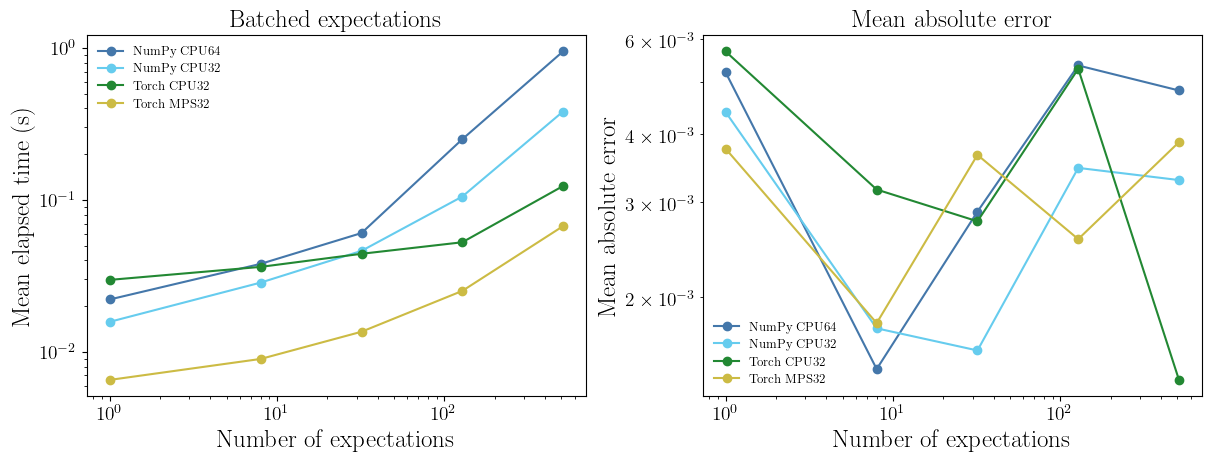

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for name, _, _ in many_methods:
    rows = many_summary[many_summary.method == name].sort_values('centers')
    axes[0].loglog(rows.centers, rows.mean_seconds, '-o', label=name)
    axes[1].loglog(rows.centers, rows.mean_absolute_error, '-o', label=name)
axes[0].set(xlabel='Number of expectations', ylabel='Mean elapsed time (s)', title='Batched expectations')
axes[1].set(xlabel='Number of expectations', ylabel='Mean absolute error', title='Mean absolute error')
for ax in axes:
    ax.legend(fontsize=9)
plt.show()

**Machine:** MacBook Pro (Mac15,8) | **Processor:** Apple M3 Max | **Logical CPU cores:** 16 | **GPU cores:** 40

,NumPy CPU64 / Torch MPS32,NumPy CPU32 / Torch MPS32,Torch CPU32 / Torch MPS32
Number of expectations,,,
1,3.384,2.411,4.553
8,4.225,3.181,4.035
32,4.460,3.405,3.258
128,9.956,4.177,2.090
512,14.126,5.681,1.836


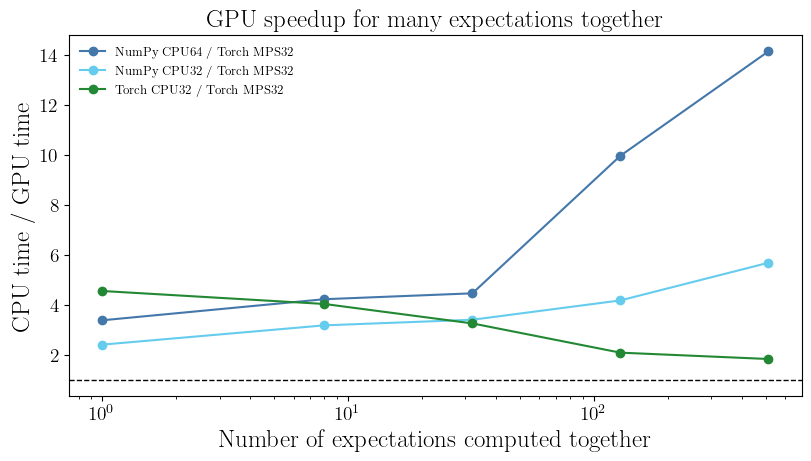

### What computing expectations together shows

- **512 expectations**, each using **262,144 shared sample points**
- **GPU time for all 512: 67.3 ms**
- GPU is **14.13 times faster** than NumPy CPU64 for the largest collection
- GPU is **5.68 times faster** than NumPy CPU32 for the largest collection
- GPU is **1.84 times faster** than Torch CPU32 for the largest collection
- **Above 1 means the GPU is faster**; the curves show whether its advantage grows or levels off as more expectations are computed together
- More expectations share the cost of generating sample points and provide more matrix work; they remain **correlated estimates, not independent replications**

In [13]:
# Compare complete-run times for computing the same expectations together
if gpu_device is not None:
    many_gpu_name = next(name for name, device, _ in many_methods if device == gpu_device)
    many_times = many_summary.pivot(index='centers', columns='method', values='mean_seconds').sort_index()
    many_gpu_speedups = pd.DataFrame(index=many_times.index)
    for baseline_name in ['NumPy CPU64', 'NumPy CPU32', 'Torch CPU32']:
        if baseline_name in many_times:
            many_gpu_speedups[f'{baseline_name} / {many_gpu_name}'] = many_times[baseline_name]/many_times[many_gpu_name]
    many_gpu_speedups.index.name = 'Number of expectations'
    display_benchmark_summary(many_gpu_speedups.round(3))
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    for column in many_gpu_speedups:
        ax.semilogx(many_gpu_speedups.index, many_gpu_speedups[column], '-o', label=column)
    ax.axhline(1, color='black', linestyle='--', linewidth=1)
    ax.set(xlabel='Number of expectations computed together', ylabel='CPU time / GPU time',
           title='GPU speedup for many expectations together')
    ax.legend(fontsize=9)
    plt.show()

    largest_count = int(many_times.index[-1])
    lines = [f'### What computing expectations together shows\n',
             f'- **{largest_count:,} expectations**, each using **{MANY_N:,} shared sample points**',
             f'- **GPU time for all {largest_count:,}: {1000*many_times.loc[largest_count, many_gpu_name]:.1f} ms**']
    for baseline_name in ['NumPy CPU64', 'NumPy CPU32', 'Torch CPU32']:
        if baseline_name in many_times:
            ratio = many_times.loc[largest_count, baseline_name]/many_times.loc[largest_count, many_gpu_name]
            relation = 'faster' if ratio >= 1 else 'slower'
            factor = ratio if ratio >= 1 else 1/ratio
            lines.append(f'- GPU is **{factor:.2f} times {relation}** than {baseline_name} for the largest collection')
    lines.append('- **Above 1 means the GPU is faster**; the curves show whether its advantage grows or levels off as more expectations are computed together')
    lines.append('- More expectations share the cost of generating sample points and provide more matrix work; they remain **correlated estimates, not independent replications**')
    display(Markdown('\n'.join(lines)))
else:
    display(Markdown('**No GPU backend is available**, so these CPU timings do not establish GPU speedup for many expectations'))


## Classroom takeaways

- **Parallelism changes time per sample**. It does not change the IID $n^{-1/2}$ RMSE rate
- **Total sample size and batch size have different roles**. More samples improve statistical accuracy; larger batches can improve throughput by amortizing dispatch overhead
- **A plateau is a useful result**. Once CPU and GPU each reach an approximately fixed processing rate, doubling the work roughly doubles both times and leaves speedup similar
- **Torch CPU and NumPy CPU include different normal generators and implementations**. The stage timings separate generation from evaluation rather than attributing the whole difference to arithmetic
- **Float32 versus float64 is a precision comparison as well as a timing comparison**. Torch CPU32 versus Torch GPU32 is the closer backend comparison
- **Many expectations provide more parallel work**, not more independent replications or automatically smaller error
- **Memory remains bounded by the batches**. The sample-count sweep streams new batches instead of retaining all samples; total sample count does not enlarge the main working arrays

- **Read speedup relative to its named baseline**. A large gain over NumPy can coexist with a modest gain over Torch CPU; the ratio measures the complete implementation, not a pure hardware multiplier
- **Core counts describe the machine, not the expected speedup**. CPU and GPU cores perform different kinds of work; their count ratio is not a throughput prediction

These measurements describe the machine that executed the notebook


In [14]:
notebook_elapsed = time.perf_counter() - NOTEBOOK_START_TIME
notebook_minutes, notebook_seconds = divmod(notebook_elapsed, 60)
print(
    "Total execution time for this notebook is "
    f"{int(notebook_minutes)} min {notebook_seconds:.1f} sec."
)

Total execution time for this notebook is 1 min 12.1 sec.
